<a href="https://colab.research.google.com/github/quinsan7/Classificao-do-Nivel-de-Emisso-de-Veiculos/blob/main/Classifica%C3%A7%C3%A3o_do_N%C3%ADvel_de_Emiss%C3%A3o_de_Ve%C3%ADculos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Este notebook demonstra um fluxo de trabalho de Machine Learning usando o algoritmo Support Vector Machine (SVM) para classificar o **nível de emissão de poluentes de veículos** (Low, Medium e High). Ele cobre desde a importação do dataset do Kaggle (Vehicle Emission Dataset), a avaliação e o tratamento dos dados, até o ajuste de hiperparâmetros com GridSearchCV, a avaliação do modelo e um teste de vazamento de dados.

In [ ]:
# Liste os arquivos de dados disponíveis no Kaggle (confirme que o dataset está anexado ao notebook)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/s3programmer/vehcle-emission-dataset/vehicle_emission_dataset.csv


### **1. Importação de Bibliotecas**

Primeiramente, importamos as bibliotecas essenciais para a construção e avaliação do modelo:
*   `numpy` e `pandas`: Para carregar, limpar e transformar os dados.
*   `matplotlib.pyplot` e `seaborn`: Para a construção dos gráficos.
*   `sklearn.model_selection.train_test_split`: Para dividir os dados em conjuntos de treino e teste.
*   `sklearn.model_selection.GridSearchCV`: Para ajustar os hiperparâmetros do modelo.
*   `sklearn.svm.SVC`: A classe para o classificador Support Vector Machine.
*   `sklearn.metrics`: Para calcular a acurácia (`accuracy_score`) e a matriz de confusão (`confusion_matrix`).

In [ ]:
# Primeiro, importe as bibliotecas necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

### **2. Carregamento dos Dados**

Nesta etapa, carregamos o conjunto de dados **Vehicle Emission Dataset**, importado para o Kaggle pessoal. Ele contém 10.000 registros de veículos (ônibus, carros, motos e caminhões) com dados operacionais (motor, idade, quilometragem, velocidade e aceleração), de via, de tráfego e de clima, além das emissões de CO2, NOx, PM2.5, VOC e SO2.

A coluna `Emission Level` (Low, Medium ou High) é o que queremos prever.

In [ ]:
# Carregue o conjunto de dados Vehicle Emission Dataset
df = pd.read_csv('/kaggle/input/datasets/s3programmer/vehcle-emission-dataset/vehicle_emission_dataset.csv')

# Mostre as primeiras linhas e o tamanho do dataset
print(df.head())
print('Linhas e colunas:', df.shape)

  Vehicle Type Fuel Type  Engine Size  Age of Vehicle  Mileage       Speed  \
0   Motorcycle  Electric     2.747609              22   291288   49.083255   
1          Bus  Electric     5.743714               3   188398   23.460311   
2          Bus    Hybrid     4.606368              17   281451  115.508350   
3        Truck  Electric     3.913024               4   151321   18.540217   
4        Truck    Hybrid     1.611297              15    91810  109.596566   

   Acceleration Road Type Traffic Conditions  Temperature   Humidity  \
0      1.887738   Highway           Moderate    13.880458  52.883905   
1      3.544147      City              Heavy    19.136947   5.697343   
2      4.646886   Highway          Free flow     8.123428   3.953116   
3      3.581004     Rural              Heavy    35.994893   0.509678   
4      3.879303   Highway           Moderate    14.793481  52.450884   

   Wind Speed  Air Pressure  CO2 Emissions  NOx Emissions  PM2.5 Emissions  \
0   18.938861    955

### **3. Avaliação do Banco de Dados**

Antes de treinar qualquer modelo, é preciso conhecer os dados. Aqui verificamos o nome e o tipo de cada coluna (`info`), o resumo estatístico das colunas numéricas (`describe`) e quantos registros existem em cada nível de emissão. Esta última checagem mostra se as classes estão balanceadas.

In [ ]:
# Mostre o tipo de cada coluna e a quantidade de valores não nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Vehicle Type        10000 non-null  object 
 1   Fuel Type           10000 non-null  object 
 2   Engine Size         10000 non-null  float64
 3   Age of Vehicle      10000 non-null  int64  
 4   Mileage             10000 non-null  int64  
 5   Speed               10000 non-null  float64
 6   Acceleration        10000 non-null  float64
 7   Road Type           10000 non-null  object 
 8   Traffic Conditions  10000 non-null  object 
 9   Temperature         10000 non-null  float64
 10  Humidity            10000 non-null  float64
 11  Wind Speed          10000 non-null  float64
 12  Air Pressure        10000 non-null  float64
 13  CO2 Emissions       10000 non-null  float64
 14  NOx Emissions       10000 non-null  float64
 15  PM2.5 Emissions     10000 non-null  float64
 16  VOC E

In [ ]:
# Mostre o resumo estatístico das colunas numéricas
print(df.describe().round(2))

       Engine Size  Age of Vehicle    Mileage     Speed  Acceleration  \
count     10000.00        10000.00   10000.00  10000.00      10000.00   
mean          3.37           14.49  148995.71     59.45          2.49   
std           1.50            8.58   87068.39     34.44          1.45   
min           0.80            0.00      56.00      0.00          0.00   
25%           2.08            7.00   73589.75     29.50          1.25   
50%           3.36           15.00  148914.50     59.70          2.48   
75%           4.65           22.00  224359.50     88.50          3.75   
max           6.00           29.00  299863.00    119.97          5.00   

       Temperature  Humidity  Wind Speed  Air Pressure  CO2 Emissions  \
count     10000.00  10000.00    10000.00      10000.00       10000.00   
mean         14.94     50.14       10.03       1000.20         273.75   
std          14.43     28.79        5.74         28.79         130.79   
min         -10.00      0.00        0.00        95

In [ ]:
# Conte quantos registros existem em cada nível de emissão
print(df['Emission Level'].value_counts())
print()
print(df['Emission Level'].value_counts(normalize=True).round(3))

Emission Level
High      4421
Medium    3274
Low       2305
Name: count, dtype: int64

Emission Level
High      0.442
Medium    0.327
Low       0.230
Name: proportion, dtype: float64


### **4. Tratamento de Dados Ausentes e Duplicados**

Valores ausentes (`NaN`) e linhas repetidas podem prejudicar o treinamento. Primeiro contamos quantos existem (`isnull` e `duplicated`); em seguida aplicamos a limpeza (`dropna` e `drop_duplicates`).

Neste dataset não há nenhum valor ausente nem linha duplicada, então a limpeza não remove nenhum registro e nenhum preenchimento (`fillna`) é necessário.

In [ ]:
# Verifique a quantidade de valores ausentes por coluna
print(df.isnull().sum())

# Verifique a quantidade de linhas duplicadas
print('Linhas duplicadas:', df.duplicated().sum())

Vehicle Type          0
Fuel Type             0
Engine Size           0
Age of Vehicle        0
Mileage               0
Speed                 0
Acceleration          0
Road Type             0
Traffic Conditions    0
Temperature           0
Humidity              0
Wind Speed            0
Air Pressure          0
CO2 Emissions         0
NOx Emissions         0
PM2.5 Emissions       0
VOC Emissions         0
SO2 Emissions         0
Emission Level        0
dtype: int64
Linhas duplicadas: 0


In [ ]:
# Remova linhas ausentes e duplicadas, se existirem (neste dataset não há nenhuma)
df = df.dropna().drop_duplicates()
print('Linhas após a limpeza:', len(df))

Linhas após a limpeza: 10000


### **5. Análise Exploratória**

Para uma inspeção visual, agrupamos os registros por tipo de veículo e nível de emissão (`groupby`) e mostramos a contagem em um mapa de calor. Cada célula mostra quantos registros pertencem àquela combinação.

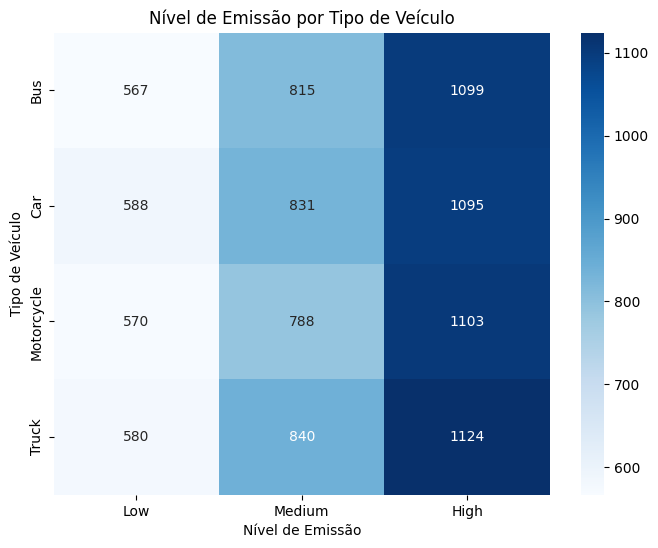

In [ ]:
# Conte os registros por tipo de veículo e nível de emissão
tabela = df.groupby(['Vehicle Type', 'Emission Level']).size().unstack()[['Low', 'Medium', 'High']]

plt.figure(figsize=(8, 6))
sns.heatmap(tabela, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Nível de Emissão')
plt.ylabel('Tipo de Veículo')
plt.title('Nível de Emissão por Tipo de Veículo')
plt.show()

### **6. Separação das Variáveis (X e y)**

Separamos as características (`X`) do rótulo (`y`). O rótulo é a coluna `Emission Level`; todas as outras 18 colunas são usadas como entrada do modelo.

In [ ]:
# Separe o rótulo (y) e as características (X)
y = df['Emission Level']
X = df.drop(columns=['Emission Level'])

### **7. Tratamento de Encoding (Variáveis Categóricas)**

O SVM só trabalha com números, então as colunas de texto precisam ser transformadas. São quatro: `Vehicle Type`, `Fuel Type`, `Road Type` e `Traffic Conditions`.

Para cada categoria criamos uma nova coluna com valor 1 (o veículo pertence àquela categoria) ou 0 (não pertence), usando uma comparação (`==`) convertida para número (`astype(int)`). Fazemos assim, e não numerando as categorias com `.map()` (0, 1, 2, 3), porque números dariam uma ordem falsa às categorias (por exemplo, "Truck" não é maior que "Bus").

O rótulo `y` (Low, Medium, High) não precisa ser transformado, porque o `SVC` aceita texto como classe.

In [ ]:
# Separe as colunas categóricas e numéricas
categorical_features = ['Vehicle Type', 'Fuel Type', 'Road Type', 'Traffic Conditions']
numerical_features = [col for col in X.columns if col not in categorical_features]

print('Categóricas:', categorical_features)
print('Numéricas:', numerical_features)

Categóricas: ['Vehicle Type', 'Fuel Type', 'Road Type', 'Traffic Conditions']
Numéricas: ['Engine Size', 'Age of Vehicle', 'Mileage', 'Speed', 'Acceleration', 'Temperature', 'Humidity', 'Wind Speed', 'Air Pressure', 'CO2 Emissions', 'NOx Emissions', 'PM2.5 Emissions', 'VOC Emissions', 'SO2 Emissions']


In [ ]:
# Crie uma coluna 0/1 para cada categoria e remova a coluna de texto original
for coluna in categorical_features:
    for valor in X[coluna].unique():
        X[coluna + '_' + valor] = (X[coluna] == valor).astype(int)

X = X.drop(columns=categorical_features)
print('Colunas após o encoding:', X.shape[1])
print(X.columns.tolist())

Colunas após o encoding: 28
['Engine Size', 'Age of Vehicle', 'Mileage', 'Speed', 'Acceleration', 'Temperature', 'Humidity', 'Wind Speed', 'Air Pressure', 'CO2 Emissions', 'NOx Emissions', 'PM2.5 Emissions', 'VOC Emissions', 'SO2 Emissions', 'Vehicle Type_Motorcycle', 'Vehicle Type_Bus', 'Vehicle Type_Truck', 'Vehicle Type_Car', 'Fuel Type_Electric', 'Fuel Type_Hybrid', 'Fuel Type_Petrol', 'Fuel Type_Diesel', 'Road Type_Highway', 'Road Type_City', 'Road Type_Rural', 'Traffic Conditions_Moderate', 'Traffic Conditions_Heavy', 'Traffic Conditions_Free flow']


### **8. Divisão dos Dados em Treino e Teste**

É crucial dividir os dados em dois subconjuntos: treino e teste. O conjunto de treino é usado para ensinar o modelo, e o conjunto de teste é usado para avaliar seu desempenho em dados que ele nunca viu antes, garantindo que o modelo generalize bem.

*   `test_size=0.2`: 20% dos dados serão usados para teste.
*   `random_state=42`: Garante que a divisão seja a mesma cada vez que o código for executado, tornando os resultados reproduzíveis.
*   `stratify=y`: Mantém a mesma proporção de Low, Medium e High no treino e no teste.

In [ ]:
# Divida os dados em conjunto de treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (8000, 28)
Teste: (2000, 28)


### **9. Normalização das Variáveis Numéricas**

As colunas numéricas têm escalas muito diferentes (a quilometragem vai até 300 mil, enquanto a aceleração vai até 5). Como o SVM calcula distâncias entre os pontos, as colunas de escala maior dominariam o resultado. Por isso padronizamos cada coluna numérica com a média e o desvio padrão (z-score):

`z = (valor - média) / desvio padrão`

A média e o desvio padrão são calculados **apenas com os dados de treino** e aplicados também ao teste, para o conjunto de teste continuar sendo "dados que o modelo nunca viu".

In [ ]:
# Calcule a média e o desvio padrão apenas com o conjunto de treino
media = X_train[numerical_features].mean()
desvio = X_train[numerical_features].std(ddof=0)

# Aplique a padronização (z-score) no treino e no teste
X_train = X_train.copy()
X_test = X_test.copy()
X_train[numerical_features] = (X_train[numerical_features] - media) / desvio
X_test[numerical_features] = (X_test[numerical_features] - media) / desvio

print(X_train[numerical_features].mean().round(2).head())

Engine Size      -0.0
Age of Vehicle   -0.0
Mileage          -0.0
Speed            -0.0
Acceleration     -0.0
dtype: float64


### **10. Criação do Modelo SVM**

Inicializamos o classificador Support Vector Machine (`SVC`) com o kernel RBF (`kernel='rbf'`). O kernel RBF usa o "truque do kernel" para separar classes que não podem ser separadas por uma reta. Os valores `C=1.0` e `gamma='scale'` são apenas o ponto de partida; eles serão ajustados no próximo passo.

In [ ]:
# Crie o modelo SVM (usando o kernel RBF)
model = SVC(kernel='rbf', C=1.0, gamma='scale')

### **11. Ajuste de Hiperparâmetros (GridSearchCV)**

O parâmetro `C` define o quanto o SVM tolera erros (margem suave), e `gamma` define o alcance de cada ponto de treino no kernel RBF. Os dois mudam bastante o resultado. O `GridSearchCV` testa todas as combinações da grade abaixo (3 valores de `C` x 2 valores de `gamma` = 6 combinações) usando validação cruzada com 5 divisões (`cv=5`) **apenas nos dados de treino**, e guarda a melhor combinação.

In [ ]:
# Defina a grade de hiperparâmetros a testar
param_grid = {
    'C': [1, 10, 100],
    'gamma': ['scale', 'auto']
}

# Crie e execute a busca com validação cruzada (cv=5)
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print('Melhores hiperparâmetros:', grid_search.best_params_)
print(f'Melhor acurácia (validação cruzada): {grid_search.best_score_ * 100:.2f}%')

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Melhores hiperparâmetros: {'C': 10, 'gamma': 'auto'}
Melhor acurácia (validação cruzada): 96.52%


### **12. Treinamento do Modelo Final**

Pegamos a melhor combinação encontrada (`best_estimator_`) e treinamos o modelo final com os dados de treino (`X_train` e `y_train`). Durante esta fase, o algoritmo SVM aprende a melhor fronteira de decisão para separar os três níveis de emissão.

In [ ]:
# Pegue o melhor modelo e treine com os dados de treino
best_model = grid_search.best_estimator_
best_model.fit(X_train, y_train)

SVC(C=10, gamma='auto')

### **13. Previsão com o Modelo Treinado**

Após o treinamento, usamos o modelo para fazer previsões nos dados de teste (`X_test`). O modelo aplica o que aprendeu para prever o nível de emissão de cada veículo do conjunto de teste.

In [ ]:
# Faça previsões nos dados de teste
y_pred = best_model.predict(X_test)

### **14. Avaliação do Modelo**

Calculamos a acurácia do modelo comparando as previsões (`y_pred`) com os rótulos verdadeiros do conjunto de teste (`y_test`). A acurácia é a proporção de previsões corretas em relação ao total de previsões.

Para uma inspeção visual, também imprimimos as 10 primeiras previsões ao lado dos valores reais.

In [ ]:
# Calcule a acurácia
accuracy = accuracy_score(y_test, y_pred)
print(f'Acurácia do modelo: {accuracy * 100:.2f}%')

Acurácia do modelo: 96.90%


In [ ]:
# Mostrar a previsão e os valores verdadeiros (10 primeiros)
print('Valores preditos:', y_pred[:10])
print('Valores reais:   ', y_test.to_numpy()[:10])

Valores preditos: ['High' 'High' 'Low' 'Medium' 'High' 'Medium' 'Medium' 'High' 'High'
 'Medium']
Valores reais:    ['High' 'High' 'Low' 'Medium' 'High' 'Medium' 'Medium' 'High' 'High'
 'Medium']


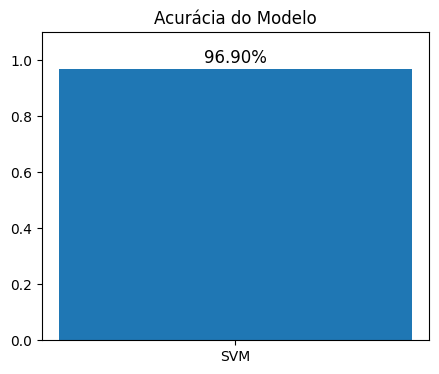

In [ ]:
# Mostre a acurácia em um gráfico
plt.figure(figsize=(5, 4))
plt.bar(['SVM'], [accuracy])
plt.ylim(0, 1.1)
plt.title('Acurácia do Modelo')
plt.text(0, accuracy + 0.02, f'{accuracy * 100:.2f}%', ha='center', fontsize=12)
plt.show()

### **15. Matriz de Confusão**

A acurácia sozinha não mostra onde o modelo erra. A matriz de confusão mostra, para cada nível real (linhas), quantas vezes o modelo previu cada nível (colunas). Os acertos ficam na diagonal.

In [ ]:
# Gere a matriz de confusão (na ordem Low, Medium, High)
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test, y_pred, labels=labels)

print('Matriz de Confusão:')
print(cm)

Matriz de Confusão:
[[448  13   0]
 [ 17 619  19]
 [  0  13 871]]


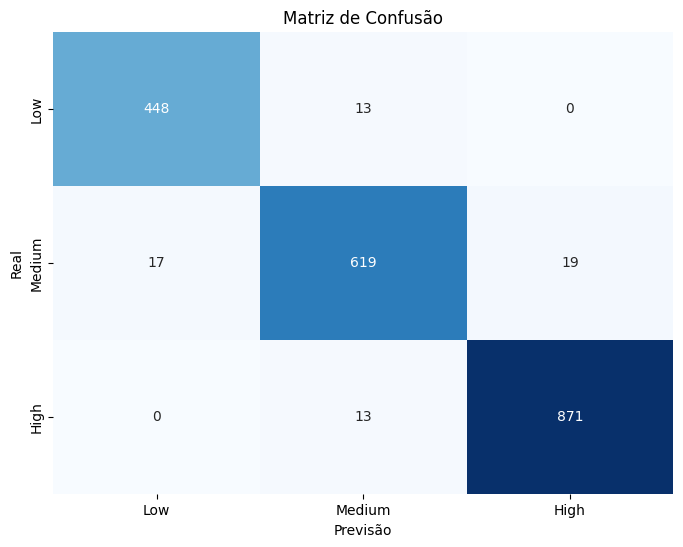

In [ ]:
# Mostre a matriz de forma gráfica
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Previsão')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

### **16. Precisão, Recall e F1-Score**

A partir da matriz de confusão calculamos, para cada nível, as métricas de avaliação. Em cada nível, chamamos de TP os acertos (diagonal), de FP os casos de outros níveis que o modelo previu como sendo daquele nível (resto da coluna) e de FN os casos daquele nível que o modelo previu como sendo de outro (resto da linha):

*   **Precisão** = TP / (TP + FP): dos que o modelo previu como aquele nível, quantos eram.
*   **Recall** = TP / (TP + FN): dos que realmente eram daquele nível, quantos o modelo achou.
*   **F1-Score** = 2 x (Precisão x Recall) / (Precisão + Recall): a média harmônica dos dois.

In [ ]:
# Calcule a precisão, o recall e o F1-Score de cada nível a partir da matriz de confusão
tp = np.diag(cm)
precisao = tp / cm.sum(axis=0)
recall = tp / cm.sum(axis=1)
f1 = 2 * precisao * recall / (precisao + recall)

metricas = pd.DataFrame({'Precisão': precisao, 'Recall': recall, 'F1-Score': f1}, index=labels)
print(metricas.round(3))

        Precisão  Recall  F1-Score
Low        0.963   0.972     0.968
Medium     0.960   0.945     0.952
High       0.979   0.985     0.982


### **17. Teste de Vazamento de Dados**

Se o modelo acerta quase tudo, vale desconfiar. Pode ser que o nível de emissão tenha sido criado a partir de uma das próprias colunas de entrada, o `CO2 Emissions`. Nesse caso o modelo não estaria descobrindo um padrão, e sim reaprendendo a regra que gerou o rótulo (vazamento de dados).

Para testar, vamos olhar a faixa de CO2 de cada nível, aplicar uma regra manual de dois cortes, comparar com um modelo que sempre chuta a classe mais comum e retreinar o SVM sem a coluna de CO2.

In [ ]:
# Mostre a faixa de CO2 de cada nível de emissão
print(df.groupby('Emission Level')['CO2 Emissions'].agg(['min', 'max']).loc[['Low', 'Medium', 'High']].round(2))

                   min     max
Emission Level                
Low              50.05  149.98
Medium          150.06  299.93
High            300.03  500.00


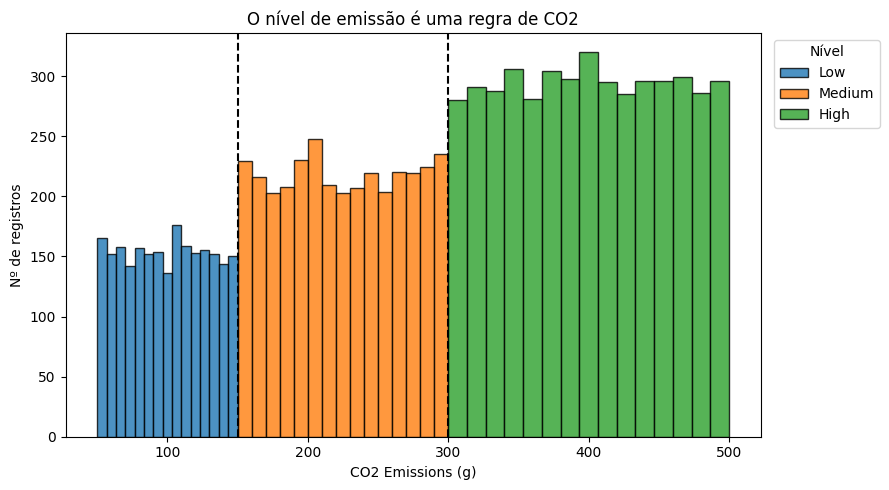

In [ ]:
# Mostre a distribuição de CO2 de cada nível, com os cortes em 150 e 300
plt.figure(figsize=(9, 5))
for nivel in ['Low', 'Medium', 'High']:
    plt.hist(df.loc[df['Emission Level'] == nivel, 'CO2 Emissions'], bins=15, alpha=0.8, label=nivel, edgecolor='black')
plt.axvline(150, color='black', linestyle='--')
plt.axvline(300, color='black', linestyle='--')
plt.xlabel('CO2 Emissions (g)')
plt.ylabel('Nº de registros')
plt.title('O nível de emissão é uma regra de CO2')
plt.legend(title='Nível', loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [ ]:
# Teste uma regra manual de 2 cortes, sem treinar nada: Low abaixo de 150, Medium de 150 a 300 e High acima de 300
# (o CO2 do conjunto de teste ainda está em valores originais em df, então usamos o índice de X_test)
co2_teste = df.loc[X_test.index, 'CO2 Emissions']
y_regra = pd.cut(co2_teste, bins=[0, 150, 300, np.inf], labels=['Low', 'Medium', 'High'], right=False)
acc_regra = accuracy_score(y_test, y_regra)
print(f'Acurácia da regra de 2 cortes em CO2: {acc_regra * 100:.2f}%')

Acurácia da regra de 2 cortes em CO2: 100.00%


In [ ]:
# Calcule a acurácia de um "modelo" que sempre prevê a classe mais comum (baseline)
classe_mais_comum = y_train.value_counts().idxmax()
acc_baseline = (y_test == classe_mais_comum).mean()
print(f'Classe mais comum: {classe_mais_comum}')
print(f'Acurácia do baseline: {acc_baseline * 100:.2f}%')

Classe mais comum: High
Acurácia do baseline: 44.20%


In [ ]:
# Crie uma função que repete o GridSearchCV e o teste para um conjunto de colunas
def treinar_e_avaliar(colunas):
    busca = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
    busca.fit(X_train[colunas], y_train)
    return accuracy_score(y_test, busca.predict(X_test[colunas]))

# Retreine o SVM sem a coluna de CO2 e só com a coluna de CO2
sem_co2 = [c for c in X_train.columns if c != 'CO2 Emissions']
acc_sem_co2 = treinar_e_avaliar(sem_co2)
acc_so_co2 = treinar_e_avaliar(['CO2 Emissions'])

print(f'SVM sem CO2 (todas as outras colunas): {acc_sem_co2 * 100:.2f}%')
print(f'SVM só com CO2 (1 coluna): {acc_so_co2 * 100:.2f}%')

SVM sem CO2 (todas as outras colunas): 44.15%
SVM só com CO2 (1 coluna): 99.80%


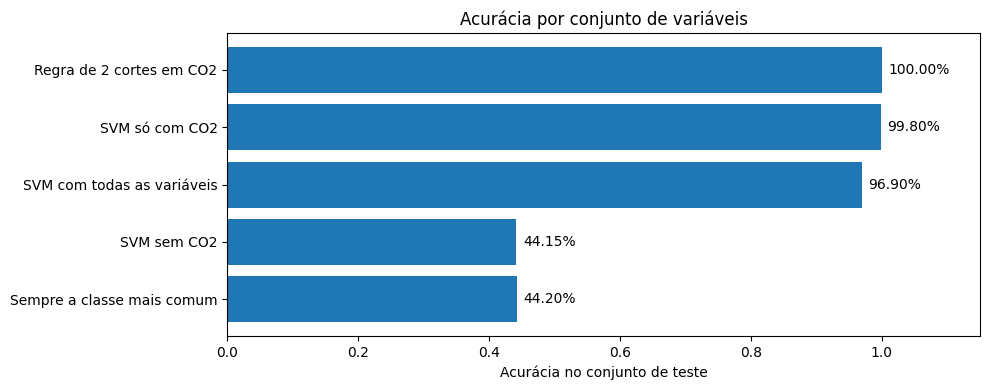

In [ ]:
# Compare todos os resultados em um gráfico
nomes = ['Regra de 2 cortes em CO2', 'SVM só com CO2', 'SVM com todas as variáveis', 'SVM sem CO2', 'Sempre a classe mais comum']
valores = [acc_regra, acc_so_co2, accuracy, acc_sem_co2, acc_baseline]

plt.figure(figsize=(10, 4))
plt.barh(nomes[::-1], valores[::-1])
for i, v in enumerate(valores[::-1]):
    plt.text(v + 0.01, i, f'{v * 100:.2f}%', va='center')
plt.xlim(0, 1.15)
plt.xlabel('Acurácia no conjunto de teste')
plt.title('Acurácia por conjunto de variáveis')
plt.tight_layout()
plt.show()

In [ ]:
# Mostre a correlação de cada variável numérica com o nível de emissão (Low=0, Medium=1, High=2)
correlacao = df[numerical_features].copy()
correlacao['Nível'] = df['Emission Level'].map({'Low': 0, 'Medium': 1, 'High': 2})
print(correlacao.corr()['Nível'].drop('Nível').round(3).sort_values(ascending=False))

CO2 Emissions      0.927
SO2 Emissions      0.022
Humidity           0.019
PM2.5 Emissions    0.014
Mileage            0.012
Wind Speed         0.012
Speed              0.008
NOx Emissions      0.005
Age of Vehicle     0.005
Air Pressure       0.001
Temperature       -0.001
Engine Size       -0.008
VOC Emissions     -0.009
Acceleration      -0.010
Name: Nível, dtype: float64


### **18. Conclusão**

*   O SVM com kernel RBF, ajustado com GridSearchCV (`C=10`, `gamma='auto'`), obteve **96,90% de acurácia** no conjunto de teste.
*   Esse resultado vem de uma única variável. O nível de emissão corresponde exatamente a faixas do `CO2 Emissions` (Low abaixo de 150 g, Medium de 150 a 300 g, High acima de 300 g). Uma regra manual de 2 cortes acerta 100% do conjunto de teste, e o SVM treinado só com o CO2 acerta 99,80%.
*   Sem o CO2, o SVM cai para 44,15%, praticamente igual ao baseline que sempre prevê a classe mais comum (44,20%). A correlação das outras variáveis numéricas com o nível é próxima de zero (de -0,010 para a aceleração a 0,022 para o SO2).
*   Portanto, os 96,90% **não indicam que o modelo descobriu um padrão** nas condições operacionais ou climáticas. Ele reaprendeu a regra que gerou o rótulo. Qualquer conclusão sobre aceleração, clima ou tráfego como determinantes da emissão não é sustentada por estes dados.